<a href="https://colab.research.google.com/github/ParthHarde/breast-cancer-project/blob/main/breakhis/02_breakhis_split_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phase 2

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
BASE = "/content/drive/MyDrive/breast-cancer-project/breakhis"
for sub in ["data/raw", "data/processed", "models", "results"]:
    os.makedirs(f"{BASE}/{sub}", exist_ok=True)
print(os.listdir(BASE))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['data', 'models', 'results']


In [ ]:
!mkdir -p ~/.kaggle
!cp /content/kaggle.json ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download -d ambarish/breakhis -p /content/breakhis_zip
!ls -lh /content/breakhis_zip

Dataset URL: https://www.kaggle.com/datasets/ambarish/breakhis
License(s): unknown
100% 3.99G/3.99G [01:05<00:00, 65.7MB/s]

total 4.0G
-rw-r--r-- 1 root root 4.0G Mar 10  2020 breakhis.zip


In [ ]:
!unzip -q /content/breakhis_zip/breakhis.zip -d "{BASE}/data/raw"

In [ ]:
import pandas as pd, glob, os

pngs = glob.glob(f"{BASE_BH}/**/*.png", recursive=True)
rows = []
for path in pngs:
    name = os.path.basename(path).replace(".png", "")
    parts = name.split("-")                      # ['SOB_B_TA','14','4659','40','001']
    biopsy, cls, subtype = parts[0].split("_")
    rows.append({"path": path, "class": cls, "label": 1 if cls == "M" else 0,
                 "subtype": subtype, "patient_id": f"{parts[1]}-{parts[2]}",
                 "magnification": int(parts[3]), "img_no": parts[4]})
meta = pd.DataFrame(rows)

assert meta["path"].is_unique
assert meta["class"].isin(["B", "M"]).all()
assert meta["magnification"].isin([40, 100, 200, 400]).all()

meta.to_csv(f"{BASE_BH}/data/processed/breakhis_meta.csv", index=False)
print(meta.shape)                                    # expect (7909, 7)
print(meta["class"].value_counts().to_string())      # expect B 2480, M 5429
print("Patients:", meta["patient_id"].nunique())     # expect 82
print("Patients with two classes:", (meta.groupby("patient_id")["class"].nunique() > 1).sum())  # expect 0
meta.head()

(7909, 7)
class
M    5429
B    2480
Patients: 81
Patients with two classes: 0


,path,class,label,subtype,patient_id,magnification,img_no
0,/content/drive/MyDrive/breast-cancer-project/b...,B,0,A,14-22549AB,100,001
1,/content/drive/MyDrive/breast-cancer-project/b...,B,0,A,14-22549AB,100,002
2,/content/drive/MyDrive/breast-cancer-project/b...,B,0,A,14-22549AB,100,003
3,/content/drive/MyDrive/breast-cancer-project/b...,B,0,A,14-22549AB,100,004
4,/content/drive/MyDrive/breast-cancer-project/b...,B,0,A,14-22549AB,100,005


In [ ]:
patients = meta.groupby("patient_id").agg(label=("label", "first"), n_images=("path", "size")).reset_index()
print(patients.shape)                  # (82, 3)
print(patients["label"].value_counts())  # 58 malignant, 24 benign

(81, 3)
label
1    57
0    24
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

p_train, p_temp = train_test_split(patients, test_size=0.30, stratify=patients["label"], random_state=42)
p_val, p_test = train_test_split(p_temp, test_size=0.50, stratify=p_temp["label"], random_state=42)

split_map = {pid: "train" for pid in p_train.patient_id}
split_map.update({pid: "val" for pid in p_val.patient_id})
split_map.update({pid: "test" for pid in p_test.patient_id})
meta["split"] = meta["patient_id"].map(split_map)
print(meta["split"].isna().sum())     # must be 0

0


In [ ]:
ids = {s: set(meta.loc[meta.split == s, "patient_id"]) for s in ["train", "val", "test"]}
assert not (ids["train"] & ids["val"])
assert not (ids["train"] & ids["test"])
assert not (ids["val"] & ids["test"])
print("No patient appears in two sets")

print(meta.groupby("split")["patient_id"].nunique())            # patients per set
print(meta.groupby("split").size())                              # images per set
print(meta.groupby("split")["label"].mean().round(3))            # malignant share (images)
print(meta.groupby(["split", "class"])["patient_id"].nunique())  # patients per class per set

No patient appears in two sets
split
test     13
train    56
val      12
Name: patient_id, dtype: int64
split
test     1346
train    5491
val      1072
dtype: int64
split
test     0.742
train    0.669
val      0.706
Name: label, dtype: float64
split  class
test   B         4
       M         9
train  B        17
       M        39
val    B         3
       M         9
Name: patient_id, dtype: int64


In [ ]:
meta.to_csv(f"{BASE_BH}/data/processed/breakhis_split.csv", index=False)

In [ ]:
from PIL import Image
from tqdm import tqdm

IMG = 224
X = np.zeros((len(meta), IMG, IMG, 3), dtype=np.uint8)
for i, p in enumerate(tqdm(meta["path"].values)):
    X[i] = np.array(Image.open(p).convert("RGB").resize((IMG, IMG)))
y = meta["label"].values.astype("float32")

np.save(f"{BASE_BH}/data/processed/X_224.npy", X)
np.save(f"{BASE_BH}/data/processed/y.npy", y)
print(X.shape, X.dtype)    # (7909, 224, 224, 3) uint8

100%|██████████| 7909/7909 [02:46<00:00, 47.42it/s]


(7909, 224, 224, 3) uint8


In [ ]:
tr = (meta["split"] == "train").values
va = (meta["split"] == "val").values
te = (meta["split"] == "test").values
X_train, y_train = X[tr], y[tr]
X_val, y_val = X[va], y[va]
X_test, y_test = X[te], y[te]      # set aside; not used until the very end
print(X_train.shape, X_val.shape, X_test.shape)

(5491, 224, 224, 3) (1072, 224, 224, 3) (1346, 224, 224, 3)


In [ ]:
import tensorflow as tf
from tensorflow import keras

BS = 32
augment = keras.Sequential([
    keras.layers.RandomFlip("horizontal_and_vertical"),
    keras.layers.RandomRotation(0.1),
    keras.layers.RandomZoom(0.1),
])

def make_ds(Xa, ya, train):
    ds = tf.data.Dataset.from_tensor_slices((Xa, ya))
    if train:
        ds = ds.shuffle(len(Xa), seed=42)
    ds = ds.batch(BS).map(lambda a, b: (tf.cast(a, tf.float32) / 255.0, b), num_parallel_calls=tf.data.AUTOTUNE)
    if train:
        ds = ds.map(lambda a, b: (augment(a, training=True), b), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(X_train, y_train, True)
val_ds = make_ds(X_val, y_val, False)
test_ds = make_ds(X_test, y_test, False)

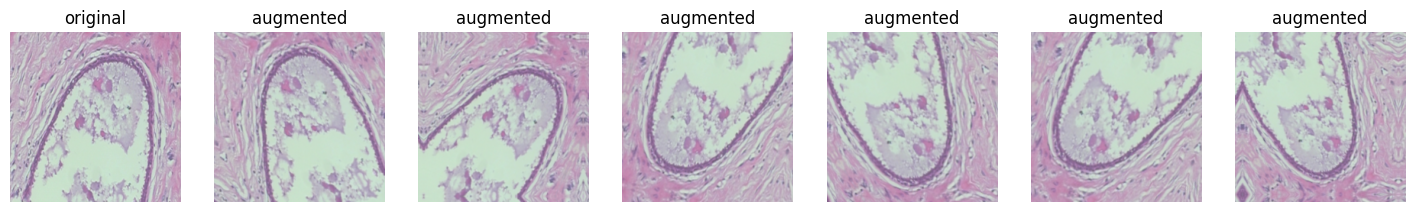

In [ ]:
import matplotlib.pyplot as plt
img = tf.cast(X_train[0:1], tf.float32) / 255.0
fig, axes = plt.subplots(1, 7, figsize=(18, 3))
axes[0].imshow(img[0]); axes[0].set_title("original")
for ax in axes[1:]:
    ax.imshow(augment(img, training=True)[0]); ax.set_title("augmented")
for ax in axes: ax.axis("off")
plt.show()

In [ ]:
import numpy as np, pandas as pd, tensorflow as tf
from tensorflow import keras
meta = pd.read_csv(f"{BASE_BH}/data/processed/breakhis_split.csv")
X = np.load(f"{BASE_BH}/data/processed/X_224.npy")
y = np.load(f"{BASE_BH}/data/processed/y.npy")

In [ ]:
print(tf.config.list_physical_devices("GPU"))   # should list one GPU

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
n = len(y_train); n_pos = y_train.sum(); n_neg = n - n_pos
class_weight = {0: n / (2 * n_neg), 1: n / (2 * n_pos)}
print(class_weight)    # benign weight > 1, malignant weight < 1

{0: np.float32(1.5101761), 1: np.float32(0.74748164)}


In [ ]:
def build_cnn(dropout=0.4):
    m = keras.Sequential([
        keras.layers.Input((224, 224, 3)),
        keras.layers.Conv2D(32, 3, activation="relu"), keras.layers.MaxPooling2D(),
        keras.layers.Conv2D(64, 3, activation="relu"), keras.layers.MaxPooling2D(),
        keras.layers.Conv2D(128, 3, activation="relu"), keras.layers.MaxPooling2D(),
        keras.layers.GlobalAveragePooling2D(),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dropout(dropout),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return m

keras.utils.set_random_seed(42)
cnn = build_cnn()
cnn.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,569 (396.75 KB)

 Trainable params: 101,569 (396.75 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
hist = cnn.fit(train_ds, validation_data=val_ds, epochs=30,
               class_weight=class_weight, callbacks=[es])

Epoch 1/30
172/172 ━━━━━━━━━━━━━━━━━━━━ 74s 337ms/step - accuracy: 0.7567 - auc: 0.7881 - loss: 0.5580 - val_accuracy: 0.8106 - val_auc: 0.8305 - val_loss: 0.4988
Epoch 2/30
172/172 ━━━━━━━━━━━━━━━━━━━━ 50s 291ms/step - accuracy: 0.8181 - auc: 0.8329 - loss: 0.4900 - val_accuracy: 0.7332 - val_auc: 0.8390 - val_loss: 0.5897
Epoch 3/30
172/172 ━━━━━━━━━━━━━━━━━━━━ 83s 298ms/step - accuracy: 0.8303 - auc: 0.8420 - loss: 0.4716 - val_accuracy: 0.7612 - val_auc: 0.8376 - val_loss: 0.6362
Epoch 4/30
172/172 ━━━━━━━━━━━━━━━━━━━━ 81s 291ms/step - accuracy: 0.8130 - auc: 0.8326 - loss: 0.4930 - val_accuracy: 0.8694 - val_auc: 0.8343 - val_loss: 0.4848
Epoch 5/30
172/172 ━━━━━━━━━━━━━━━━━━━━ 51s 291ms/step - accuracy: 0.8412 - auc: 0.8469 - loss: 0.4617 - val_accuracy: 0.8694 - val_auc: 0.8273 - val_loss: 0.4118
Epoch 6/30
172/172 ━━━━━━━━━━━━━━━━━━━━ 82s 291ms/step - accuracy: 0.8392 - auc: 0.8557 - loss: 0.4527 - val_accuracy: 0.8666 - val_auc: 0.8278 - val_loss: 0.4249
Epoch 7/30
172/172 ━━━

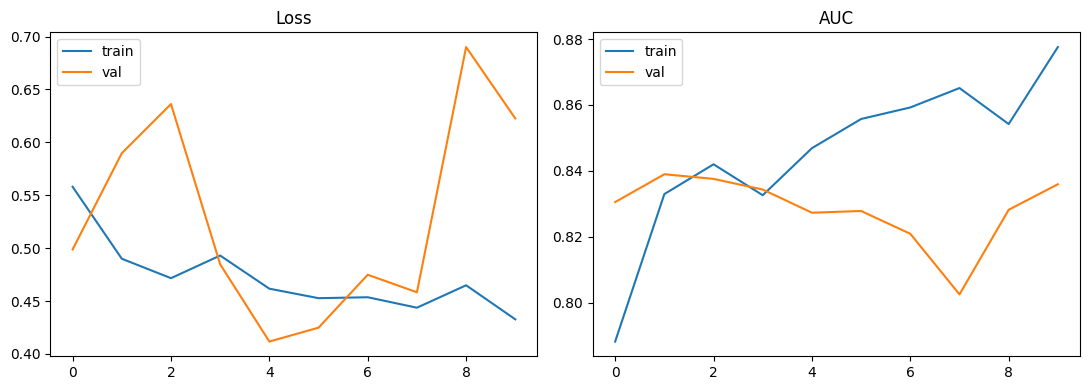

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist.history["loss"], label="train"); ax[0].plot(hist.history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(hist.history["auc"], label="train"); ax[1].plot(hist.history["val_auc"], label="val")
ax[1].set_title("AUC"); ax[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, balanced_accuracy_score)

pv = cnn.predict(val_ds).ravel()
pred = (pv >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()

res = {
    "model": "baseline_cnn", "split": "validation",
    "accuracy": accuracy_score(y_val, pred),
    "balanced_acc": balanced_accuracy_score(y_val, pred),
    "precision": precision_score(y_val, pred),
    "recall_malignant": recall_score(y_val, pred),
    "specificity_benign": tn / (tn + fp),
    "f1": f1_score(y_val, pred),
    "auc": roc_auc_score(y_val, pv),
}
print(pd.Series(res).round(3))
print(confusion_matrix(y_val, pred))

34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step
model                 baseline_cnn
split                   validation
accuracy                  0.869403
balanced_acc              0.828752
precision                 0.891995
recall_malignant          0.927345
specificity_benign        0.730159
f1                        0.909326
auc                       0.827414
dtype: object
[[230  85]
 [ 55 702]]


In [ ]:
pd.DataFrame([res]).round(3).to_csv(f"{BASE_BH}/results/breakhis_baseline.csv", index=False)
cnn.save(f"{BASE_BH}/models/breakhis_baseline_cnn.keras")

In [ ]:
def build_transfer(dropout=0.3):
    base = keras.applications.MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights="imagenet")
    base.trainable = False
    inp = keras.layers.Input((224, 224, 3))
    x = keras.layers.Rescaling(2.0, offset=-1.0)(inp)     # [0,1] -> [-1,1]
    x = base(x, training=False)                            # keeps BatchNorm in inference mode
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dropout(dropout)(x)
    out = keras.layers.Dense(1, activation="sigmoid")(x)
    m = keras.Model(inp, out)
    return m, base

keras.utils.set_random_seed(42)
tl, base = build_transfer()
tl.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
           metrics=["accuracy", keras.metrics.AUC(name="auc")])
tl.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_13 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
es1 = keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)
h1 = tl.fit(train_ds, validation_data=val_ds, epochs=15, class_weight=class_weight, callbacks=[es1])

Epoch 1/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 74s 352ms/step - accuracy: 0.6707 - auc: 0.7333 - loss: 0.6248 - val_accuracy: 0.7164 - val_auc: 0.7897 - val_loss: 0.5582
Epoch 2/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 49s 285ms/step - accuracy: 0.7418 - auc: 0.8134 - loss: 0.5328 - val_accuracy: 0.6437 - val_auc: 0.8153 - val_loss: 0.6519
Epoch 3/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 82s 287ms/step - accuracy: 0.7671 - auc: 0.8464 - loss: 0.4854 - val_accuracy: 0.6838 - val_auc: 0.8142 - val_loss: 0.6025
Epoch 4/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 50s 286ms/step - accuracy: 0.7742 - auc: 0.8564 - loss: 0.4746 - val_accuracy: 0.7099 - val_auc: 0.8263 - val_loss: 0.5732
Epoch 5/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 50s 286ms/step - accuracy: 0.7957 - auc: 0.8716 - loss: 0.4507 - val_accuracy: 0.7099 - val_auc: 0.8386 - val_loss: 0.5862


In [ ]:
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

tl.compile(optimizer=keras.optimizers.Adam(1e-5), loss="binary_crossentropy",
           metrics=["accuracy", keras.metrics.AUC(name="auc")])   # re-compile after changing trainable

es2 = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
h2 = tl.fit(train_ds, validation_data=val_ds, epochs=20, class_weight=class_weight, callbacks=[es2])

Epoch 1/20
172/172 ━━━━━━━━━━━━━━━━━━━━ 75s 354ms/step - accuracy: 0.7476 - auc: 0.8256 - loss: 0.5146 - val_accuracy: 0.6660 - val_auc: 0.7985 - val_loss: 0.6573
Epoch 2/20
172/172 ━━━━━━━━━━━━━━━━━━━━ 63s 288ms/step - accuracy: 0.7867 - auc: 0.8667 - loss: 0.4570 - val_accuracy: 0.6968 - val_auc: 0.8333 - val_loss: 0.6050
Epoch 3/20
172/172 ━━━━━━━━━━━━━━━━━━━━ 82s 289ms/step - accuracy: 0.8084 - auc: 0.8908 - loss: 0.4170 - val_accuracy: 0.6297 - val_auc: 0.8397 - val_loss: 0.7416
Epoch 4/20
172/172 ━━━━━━━━━━━━━━━━━━━━ 82s 285ms/step - accuracy: 0.8228 - auc: 0.9058 - loss: 0.3892 - val_accuracy: 0.7052 - val_auc: 0.8587 - val_loss: 0.5906
Epoch 5/20
172/172 ━━━━━━━━━━━━━━━━━━━━ 82s 290ms/step - accuracy: 0.8390 - auc: 0.9190 - loss: 0.3638 - val_accuracy: 0.7509 - val_auc: 0.8600 - val_loss: 0.5515
Epoch 6/20
172/172 ━━━━━━━━━━━━━━━━━━━━ 50s 288ms/step - accuracy: 0.8485 - auc: 0.9278 - loss: 0.3422 - val_accuracy: 0.7640 - val_auc: 0.8755 - val_loss: 0.4865
Epoch 7/20
172/172 ━━━

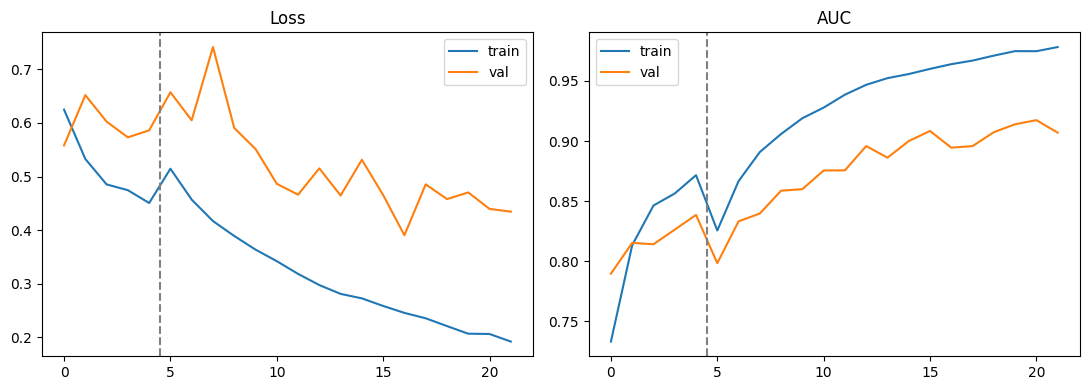

In [ ]:
import matplotlib.pyplot as plt
loss = h1.history["loss"] + h2.history["loss"];   vloss = h1.history["val_loss"] + h2.history["val_loss"]
auc = h1.history["auc"] + h2.history["auc"];      vauc = h1.history["val_auc"] + h2.history["val_auc"]
k = len(h1.history["loss"])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, tr, va, t in [(ax[0], loss, vloss, "Loss"), (ax[1], auc, vauc, "AUC")]:
    a.plot(tr, label="train"); a.plot(va, label="val"); a.axvline(k - 0.5, ls="--", c="gray"); a.set_title(t); a.legend()
plt.tight_layout(); plt.show()

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, balanced_accuracy_score)

pv = tl.predict(val_ds).ravel()
pred = (pv >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
res = {"model": "mobilenetv2_finetuned", "split": "validation",
       "accuracy": accuracy_score(y_val, pred), "balanced_acc": balanced_accuracy_score(y_val, pred),
       "precision": precision_score(y_val, pred), "recall_malignant": recall_score(y_val, pred),
       "specificity_benign": tn / (tn + fp), "f1": f1_score(y_val, pred), "auc": roc_auc_score(y_val, pv)}

base_res = pd.read_csv(f"{BASE_BH}/results/breakhis_baseline.csv")
cmp = pd.concat([base_res, pd.DataFrame([res]).round(3)], ignore_index=True)
print(cmp.to_string(index=False))
print(confusion_matrix(y_val, pred))

34/34 ━━━━━━━━━━━━━━━━━━━━ 8s 130ms/step
                model      split  accuracy  balanced_acc  precision  recall_malignant  specificity_benign    f1   auc
         baseline_cnn validation     0.869         0.829      0.892             0.927               0.730 0.909 0.827
mobilenetv2_finetuned validation     0.822         0.802      0.893             0.849               0.756 0.871 0.895
[[238  77]
 [114 643]]


In [ ]:
cmp.to_csv(f"{BASE_BH}/results/breakhis_val_comparison.csv", index=False)
tl.save(f"{BASE_BH}/models/breakhis_mobilenetv2.keras")

In [ ]:
def build_effnet(dropout=0.3):
    base = keras.applications.EfficientNetB0(input_shape=(224, 224, 3), include_top=False, weights="imagenet")
    base.trainable = False
    inp = keras.layers.Input((224, 224, 3))
    x = keras.layers.Rescaling(255.0)(inp)               # [0,1] -> [0,255]
    x = base(x, training=False)
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dropout(dropout)(x)
    out = keras.layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inp, out), base

keras.utils.set_random_seed(42)
eff, ebase = build_effnet()
eff.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
            metrics=["accuracy", keras.metrics.AUC(name="auc")])

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
es1 = keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)
e1 = eff.fit(train_ds, validation_data=val_ds, epochs=15, class_weight=class_weight, callbacks=[es1])

ebase.trainable = True
for layer in ebase.layers[:-30]:
    layer.trainable = False
for layer in ebase.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False
eff.compile(optimizer=keras.optimizers.Adam(1e-5), loss="binary_crossentropy",
            metrics=["accuracy", keras.metrics.AUC(name="auc")])
es2 = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
e2 = eff.fit(train_ds, validation_data=val_ds, epochs=20, class_weight=class_weight, callbacks=[es2])

Epoch 1/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 103s 438ms/step - accuracy: 0.7529 - auc: 0.8273 - loss: 0.5257 - val_accuracy: 0.7901 - val_auc: 0.8398 - val_loss: 0.4959
Epoch 2/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 50s 289ms/step - accuracy: 0.8423 - auc: 0.9104 - loss: 0.4009 - val_accuracy: 0.7910 - val_auc: 0.8554 - val_loss: 0.4957
Epoch 3/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 50s 289ms/step - accuracy: 0.8627 - auc: 0.9279 - loss: 0.3603 - val_accuracy: 0.8097 - val_auc: 0.8614 - val_loss: 0.4713
Epoch 4/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 50s 289ms/step - accuracy: 0.8700 - auc: 0.9321 - loss: 0.3437 - val_accuracy: 0.7817 - val_auc: 0.8696 - val_loss: 0.5039
Epoch 5/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 82s 290ms/step - accuracy: 0.8765 - auc: 0.9378 - loss: 0.3279 - val_accuracy: 0.7910 - val_auc: 0.8654 - val_loss: 0.4995
Epoch 6/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 50s 290ms/step - accuracy: 0.8851 - auc: 0.9415 - loss: 0.3163 - val_accuracy: 0.8004 - val_auc: 0.8727 - val_loss: 0.4950
Epoch 7/15
172/172 ━━

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, balanced_accuracy_score)

def score(name, model):
    pv = model.predict(val_ds).ravel()
    pred = (pv >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
    ptr = model.predict(make_ds(X_train, y_train, False)).ravel()
    return pv, {"model": name, "val_auc": roc_auc_score(y_val, pv),
        "train_auc": roc_auc_score(y_train, ptr),
        "val_acc": accuracy_score(y_val, pred), "balanced_acc": balanced_accuracy_score(y_val, pred),
        "recall_malignant": recall_score(y_val, pred), "specificity_benign": tn / (tn + fp),
        "f1": f1_score(y_val, pred)}

cnn = keras.models.load_model(f"{BASE_BH}/models/breakhis_baseline_cnn.keras")
mob = keras.models.load_model(f"{BASE_BH}/models/breakhis_mobilenetv2.keras")
probs, rows = {}, []
for name, m in [("baseline_cnn", cnn), ("mobilenetv2", mob), ("efficientnetb0", eff)]:
    probs[name], r = score(name, m)
    rows.append(r)
tab = pd.DataFrame(rows).round(3)
tab["gap"] = (tab["train_auc"] - tab["val_auc"]).round(3)
print(tab.to_string(index=False))

34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step
172/172 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step
34/34 ━━━━━━━━━━━━━━━━━━━━ 8s 132ms/step
172/172 ━━━━━━━━━━━━━━━━━━━━ 8s 46ms/step
34/34 ━━━━━━━━━━━━━━━━━━━━ 13s 217ms/step
172/172 ━━━━━━━━━━━━━━━━━━━━ 11s 60ms/step
         model  val_auc  train_auc  val_acc  balanced_acc  recall_malignant  specificity_benign    f1   gap
  baseline_cnn    0.827      0.861    0.869         0.829             0.927               0.730 0.909 0.034
   mobilenetv2    0.895      0.978    0.822         0.802             0.849               0.756 0.871 0.083
efficientnetb0    0.878      0.979    0.854         0.842             0.871               0.813 0.894 0.101


In [ ]:
val_meta = meta[meta["split"] == "val"].reset_index(drop=True)
for name, pv in probs.items():
    d = val_meta.assign(p=pv).groupby("patient_id").agg(label=("label", "first"), p=("p", "mean"))
    pat_pred = (d["p"] >= 0.5).astype(int)
    print(name, "| patients:", len(d),
          "| patient accuracy:", round((pat_pred == d["label"]).mean(), 3),
          "| patient AUC:", round(roc_auc_score(d["label"], d["p"]), 3))

baseline_cnn | patients: 12 | patient accuracy: 0.833 | patient AUC: 0.741
mobilenetv2 | patients: 12 | patient accuracy: 0.833 | patient AUC: 0.963
efficientnetb0 | patients: 12 | patient accuracy: 0.833 | patient AUC: 0.889


In [ ]:
tab.to_csv(f"{BASE_BH}/results/breakhis_val_comparison_all.csv", index=False)
eff.save(f"{BASE_BH}/models/breakhis_efficientnetb0.keras")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob
import numpy as np, pandas as pd

BASE_BH = "/content/drive/MyDrive/breast-cancer-project/breakhis"
for sub in ["data/processed", "models", "results"]:
    os.makedirs(f"{BASE_BH}/{sub}", exist_ok=True)

meta = pd.read_csv(f"{BASE_BH}/data/processed/breakhis_meta.csv")
print(meta.shape)     # expect (7909, 7)

Mounted at /content/drive
(7909, 7)


In [ ]:
patients = meta.groupby("patient_id").agg(label=("label", "first"), n_images=("path", "size")).reset_index()
print(patients.shape)                    # (82, 3)
print(patients["label"].value_counts())  # 58 malignant, 24 benign

(81, 3)
label
1    57
0    24
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

p_train, p_temp = train_test_split(patients, test_size=0.30, stratify=patients["label"], random_state=42)
p_val, p_test = train_test_split(p_temp, test_size=0.50, stratify=p_temp["label"], random_state=42)

split_map = {pid: "train" for pid in p_train.patient_id}
split_map.update({pid: "val" for pid in p_val.patient_id})
split_map.update({pid: "test" for pid in p_test.patient_id})
meta["split"] = meta["patient_id"].map(split_map)
print("Unassigned rows (must be 0):", meta["split"].isna().sum())

Unassigned rows (must be 0): 0


In [ ]:
ids = {s: set(meta.loc[meta.split == s, "patient_id"]) for s in ["train", "val", "test"]}
assert not (ids["train"] & ids["val"])
assert not (ids["train"] & ids["test"])
assert not (ids["val"] & ids["test"])
print("No patient appears in two sets\n")
print("Patients per set:\n", meta.groupby("split")["patient_id"].nunique().to_string())
print("\nImages per set:\n", meta.groupby("split").size().to_string())
print("\nMalignant share (images):\n", meta.groupby("split")["label"].mean().round(3).to_string())
print("\nPatients per class per set:\n", meta.groupby(["split", "class"])["patient_id"].nunique().unstack().to_string())

meta.to_csv(f"{BASE_BH}/data/processed/breakhis_split.csv", index=False)

No patient appears in two sets

Patients per set:
 split
test     13
train    56
val      12

Images per set:
 split
test     1346
train    5491
val      1072

Malignant share (images):
 split
test     0.742
train    0.669
val      0.706

Patients per class per set:
 class   B   M
split        
test    4   9
train  17  39
val     3   9


In [ ]:
from PIL import Image
from tqdm import tqdm

IMG = 224
X = np.zeros((len(meta), IMG, IMG, 3), dtype=np.uint8)
for i, p in enumerate(tqdm(meta["path"].values)):
    X[i] = np.array(Image.open(p).convert("RGB").resize((IMG, IMG)))
y = meta["label"].values.astype("float32")

np.save(f"{BASE_BH}/data/processed/X_224.npy", X)
np.save(f"{BASE_BH}/data/processed/y.npy", y)
print(X.shape, X.dtype)       # (7909, 224, 224, 3) uint8

100%|██████████| 7909/7909 [1:20:18<00:00,  1.64it/s]


(7909, 224, 224, 3) uint8


In [ ]:
meta = pd.read_csv(f"{BASE_BH}/data/processed/breakhis_split.csv")
X = np.load(f"{BASE_BH}/data/processed/X_224.npy")
y = np.load(f"{BASE_BH}/data/processed/y.npy")
print(X.shape, meta.shape)

(7909, 224, 224, 3) (7909, 8)


In [ ]:
tr = (meta["split"] == "train").values
va = (meta["split"] == "val").values
te = (meta["split"] == "test").values
X_train, y_train = X[tr], y[tr]
X_val, y_val = X[va], y[va]
X_test, y_test = X[te], y[te]        # set aside; not used until the final evaluation
print(X_train.shape, X_val.shape, X_test.shape)

import tensorflow as tf
from tensorflow import keras
print("GPU:", tf.config.list_physical_devices("GPU"))

BS = 32
augment = keras.Sequential([
    keras.layers.RandomFlip("horizontal_and_vertical"),
    keras.layers.RandomRotation(0.1),
    keras.layers.RandomZoom(0.1),
])

def make_ds(Xa, ya, train):
    ds = tf.data.Dataset.from_tensor_slices((Xa, ya))
    if train:
        ds = ds.shuffle(len(Xa), seed=42)
    ds = ds.batch(BS).map(lambda a, b: (tf.cast(a, tf.float32) / 255.0, b), num_parallel_calls=tf.data.AUTOTUNE)
    if train:
        ds = ds.map(lambda a, b: (augment(a, training=True), b), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(X_train, y_train, True)
val_ds = make_ds(X_val, y_val, False)
test_ds = make_ds(X_test, y_test, False)

(5491, 224, 224, 3) (1072, 224, 224, 3) (1346, 224, 224, 3)
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


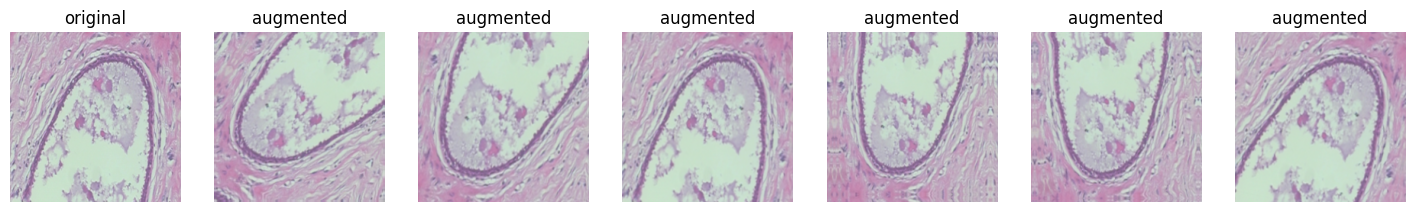

In [ ]:
import matplotlib.pyplot as plt
img = tf.cast(X_train[0:1], tf.float32) / 255.0
fig, axes = plt.subplots(1, 7, figsize=(18, 3))
axes[0].imshow(img[0]); axes[0].set_title("original")
for ax in axes[1:]:
    ax.imshow(augment(img, training=True)[0]); ax.set_title("augmented")
for ax in axes: ax.axis("off")
plt.show()

In [ ]:
n = len(y_train); n_pos = y_train.sum(); n_neg = n - n_pos
class_weight = {0: n / (2 * n_neg), 1: n / (2 * n_pos)}
print(class_weight)

def build_cnn(dropout=0.4):
    m = keras.Sequential([
        keras.layers.Input((224, 224, 3)),
        keras.layers.Conv2D(32, 3, activation="relu"), keras.layers.MaxPooling2D(),
        keras.layers.Conv2D(64, 3, activation="relu"), keras.layers.MaxPooling2D(),
        keras.layers.Conv2D(128, 3, activation="relu"), keras.layers.MaxPooling2D(),
        keras.layers.GlobalAveragePooling2D(),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dropout(dropout),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return m

keras.utils.set_random_seed(42)
cnn = build_cnn()
cnn.summary()

{0: np.float32(1.5101761), 1: np.float32(0.74748164)}


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,569 (396.75 KB)

 Trainable params: 101,569 (396.75 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
hist = cnn.fit(train_ds, validation_data=val_ds, epochs=30, class_weight=class_weight, callbacks=[es])
cnn.save(f"{BASE_BH}/models/breakhis_baseline_cnn.keras")

Epoch 1/30
172/172 ━━━━━━━━━━━━━━━━━━━━ 73s 344ms/step - accuracy: 0.7753 - auc: 0.8033 - loss: 0.5427 - val_accuracy: 0.7388 - val_auc: 0.8445 - val_loss: 0.5860
Epoch 2/30
172/172 ━━━━━━━━━━━━━━━━━━━━ 70s 404ms/step - accuracy: 0.8270 - auc: 0.8409 - loss: 0.4750 - val_accuracy: 0.8479 - val_auc: 0.8386 - val_loss: 0.4608
Epoch 3/30
172/172 ━━━━━━━━━━━━━━━━━━━━ 69s 397ms/step - accuracy: 0.8388 - auc: 0.8499 - loss: 0.4653 - val_accuracy: 0.7090 - val_auc: 0.8456 - val_loss: 0.6130
Epoch 4/30
172/172 ━━━━━━━━━━━━━━━━━━━━ 70s 407ms/step - accuracy: 0.8381 - auc: 0.8482 - loss: 0.4640 - val_accuracy: 0.8694 - val_auc: 0.8260 - val_loss: 0.4062
Epoch 5/30
172/172 ━━━━━━━━━━━━━━━━━━━━ 51s 293ms/step - accuracy: 0.8425 - auc: 0.8620 - loss: 0.4468 - val_accuracy: 0.8769 - val_auc: 0.8165 - val_loss: 0.3883
Epoch 6/30
172/172 ━━━━━━━━━━━━━━━━━━━━ 82s 294ms/step - accuracy: 0.8430 - auc: 0.8714 - loss: 0.4376 - val_accuracy: 0.6828 - val_auc: 0.8126 - val_loss: 0.6266
Epoch 7/30
172/172 ━━━

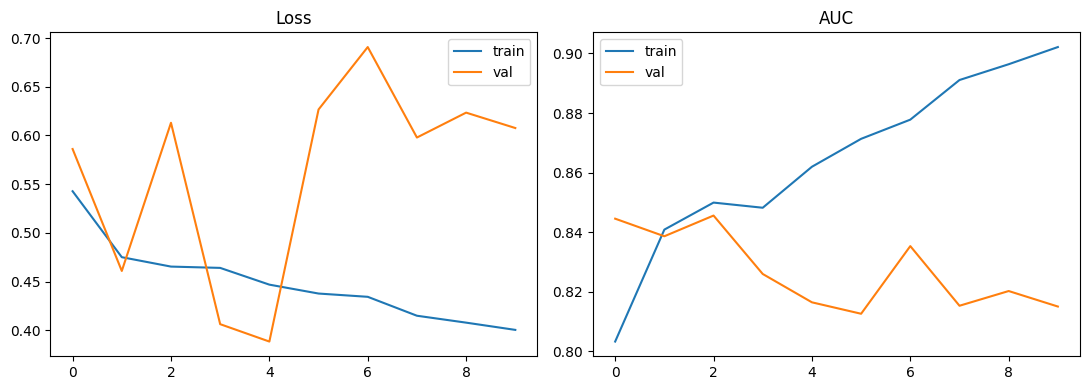

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist.history["loss"], label="train"); ax[0].plot(hist.history["val_loss"], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(hist.history["auc"], label="train"); ax[1].plot(hist.history["val_auc"], label="val"); ax[1].set_title("AUC"); ax[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, balanced_accuracy_score)

def score(name, model):
    pv = model.predict(val_ds).ravel()
    pred = (pv >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
    ptr = model.predict(make_ds(X_train, y_train, False)).ravel()   # train AUC on unaugmented images
    return pv, {"model": name, "val_auc": roc_auc_score(y_val, pv), "train_auc": roc_auc_score(y_train, ptr),
        "val_acc": accuracy_score(y_val, pred), "balanced_acc": balanced_accuracy_score(y_val, pred),
        "recall_malignant": recall_score(y_val, pred), "specificity_benign": tn / (tn + fp),
        "precision": precision_score(y_val, pred), "f1": f1_score(y_val, pred)}

probs, rows = {}, []
probs["baseline_cnn"], r = score("baseline_cnn", cnn); rows.append(r)
print(pd.DataFrame(rows).round(3).to_string(index=False))
print(confusion_matrix(y_val, (probs["baseline_cnn"] >= 0.5).astype(int)))

34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step
172/172 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step
       model  val_auc  train_auc  val_acc  balanced_acc  recall_malignant  specificity_benign  precision    f1
baseline_cnn    0.816      0.887    0.877         0.841             0.929               0.752        0.9 0.914
[[237  78]
 [ 54 703]]


In [ ]:
def build_transfer(dropout=0.3):
    base = keras.applications.MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights="imagenet")
    base.trainable = False
    inp = keras.layers.Input((224, 224, 3))
    x = keras.layers.Rescaling(2.0, offset=-1.0)(inp)      # [0,1] -> [-1,1]
    x = base(x, training=False)
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dropout(dropout)(x)
    out = keras.layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inp, out), base

def finetune_setup(model, base, n_top=30):
    base.trainable = True
    for layer in base.layers[:-n_top]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, keras.layers.BatchNormalization):
            layer.trainable = False
    model.compile(optimizer=keras.optimizers.Adam(1e-5), loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])

keras.utils.set_random_seed(42)
tl, base = build_transfer()
tl.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
           metrics=["accuracy", keras.metrics.AUC(name="auc")])
es1 = keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)
h1 = tl.fit(train_ds, validation_data=val_ds, epochs=15, class_weight=class_weight, callbacks=[es1])

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 74s 355ms/step - accuracy: 0.6678 - auc: 0.7310 - loss: 0.6284 - val_accuracy: 0.6222 - val_auc: 0.7835 - val_loss: 0.6695
Epoch 2/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 50s 288ms/step - accuracy: 0.7363 - auc: 0.8162 - loss: 0.5265 - val_accuracy: 0.7220 - val_auc: 0.8238 - val_loss: 0.5460
Epoch 3/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 82s 289ms/step - accuracy: 0.7607 - auc: 0.8404 - loss: 0.4962 - val_accuracy: 0.7285 - val_auc: 0.8296 - val_loss: 0.5295
Epoch 4/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 81s 284ms/step - accuracy: 0.7922 - auc: 0.8609 - loss: 0.4656 - val_accuracy: 0.7257 - val_auc: 0.8234 - val_loss: 0.5530
Epoch 5/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 49s 284ms/step - accuracy: 0.7856 - auc: 0.8691 - loss: 0.4530 - val_accuracy: 0.7379 - val_auc: 0.8180 - val_loss: 0.5113
Epoch 6/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 82s 285ms/step - accuracy: 0.7962 - auc: 0.8733 - loss: 0.4473 - val_accuracy: 0.7164 - val_auc:

In [ ]:
finetune_setup(tl, base)
es2 = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
h2 = tl.fit(train_ds, validation_data=val_ds, epochs=20, class_weight=class_weight, callbacks=[es2])
tl.save(f"{BASE_BH}/models/breakhis_mobilenetv2.keras")

Epoch 1/20
172/172 ━━━━━━━━━━━━━━━━━━━━ 73s 347ms/step - accuracy: 0.8033 - auc: 0.8847 - loss: 0.4275 - val_accuracy: 0.7565 - val_auc: 0.8560 - val_loss: 0.5146
Epoch 2/20
172/172 ━━━━━━━━━━━━━━━━━━━━ 49s 284ms/step - accuracy: 0.8264 - auc: 0.9056 - loss: 0.3889 - val_accuracy: 0.7024 - val_auc: 0.8614 - val_loss: 0.5855
Epoch 3/20
172/172 ━━━━━━━━━━━━━━━━━━━━ 82s 282ms/step - accuracy: 0.8299 - auc: 0.9139 - loss: 0.3709 - val_accuracy: 0.7351 - val_auc: 0.8667 - val_loss: 0.5553
Epoch 4/20
172/172 ━━━━━━━━━━━━━━━━━━━━ 49s 284ms/step - accuracy: 0.8487 - auc: 0.9291 - loss: 0.3398 - val_accuracy: 0.7416 - val_auc: 0.8679 - val_loss: 0.5349
Epoch 5/20
172/172 ━━━━━━━━━━━━━━━━━━━━ 49s 284ms/step - accuracy: 0.8554 - auc: 0.9351 - loss: 0.3249 - val_accuracy: 0.7425 - val_auc: 0.8824 - val_loss: 0.5259
Epoch 6/20
172/172 ━━━━━━━━━━━━━━━━━━━━ 82s 286ms/step - accuracy: 0.8625 - auc: 0.9417 - loss: 0.3083 - val_accuracy: 0.7491 - val_auc: 0.8903 - val_loss: 0.5278


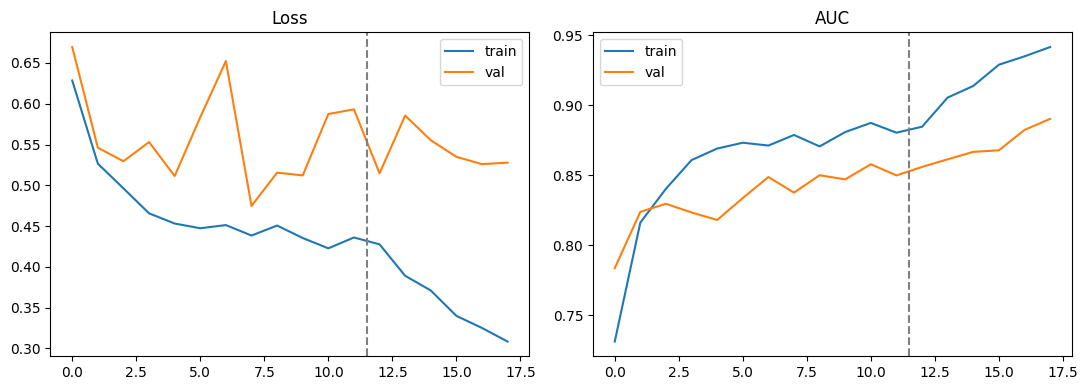

34/34 ━━━━━━━━━━━━━━━━━━━━ 8s 131ms/step
172/172 ━━━━━━━━━━━━━━━━━━━━ 8s 47ms/step
       model  val_auc  train_auc  val_acc  balanced_acc  recall_malignant  specificity_benign  precision    f1   gap
baseline_cnn    0.816      0.887    0.877         0.841             0.929               0.752      0.900 0.914 0.071
 mobilenetv2    0.856      0.930    0.757         0.780             0.723               0.838      0.915 0.807 0.074
[[264  51]
 [210 547]]


In [ ]:
loss = h1.history["loss"] + h2.history["loss"];   vloss = h1.history["val_loss"] + h2.history["val_loss"]
auc = h1.history["auc"] + h2.history["auc"];      vauc = h1.history["val_auc"] + h2.history["val_auc"]
k = len(h1.history["loss"])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, t_, v_, t in [(ax[0], loss, vloss, "Loss"), (ax[1], auc, vauc, "AUC")]:
    a.plot(t_, label="train"); a.plot(v_, label="val"); a.axvline(k - 0.5, ls="--", c="gray"); a.set_title(t); a.legend()
plt.tight_layout(); plt.show()

probs["mobilenetv2"], r = score("mobilenetv2", tl); rows.append(r)
tab = pd.DataFrame(rows).round(3)
tab["gap"] = (tab["train_auc"] - tab["val_auc"]).round(3)
print(tab.to_string(index=False))
print(confusion_matrix(y_val, (probs["mobilenetv2"] >= 0.5).astype(int)))
tab.to_csv(f"{BASE_BH}/results/breakhis_val_comparison.csv", index=False)

In [ ]:
# ===== RUN THIS FIRST (after every restart) =====
from google.colab import drive
drive.mount('/content/drive')

import os, glob, json, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, balanced_accuracy_score)

# ---- paths ----
BASE_BH = "/content/drive/MyDrive/breast-cancer-project/breakhis"
M = "/content/drive/MyDrive/breast-cancer-project/metabric"
for sub in ["data/processed", "models", "results", "deploy"]:
    os.makedirs(f"{BASE_BH}/{sub}", exist_ok=True)

print("GPU:", tf.config.list_physical_devices("GPU"))   # should list one GPU (Runtime > Change runtime type > T4)

# ---- data (needs the files made on Oct 19) ----
need = [f"{BASE_BH}/data/processed/breakhis_split.csv",
        f"{BASE_BH}/data/processed/X_224.npy",
        f"{BASE_BH}/data/processed/y.npy"]
missing = [p for p in need if not os.path.exists(p)]
assert not missing, f"Run the Oct 19 cells first. Missing: {missing}"

meta = pd.read_csv(need[0])
X = np.load(need[1])
y = np.load(need[2])
assert len(meta) == len(X) == len(y), "meta, X and y do not line up"

tr = (meta["split"] == "train").values
va = (meta["split"] == "val").values
te = (meta["split"] == "test").values
X_train, y_train = X[tr], y[tr]
X_val, y_val = X[va], y[va]
X_test, y_test = X[te], y[te]          # not used until the final evaluation
print("train / val / test:", X_train.shape[0], X_val.shape[0], X_test.shape[0])

# ---- datasets (augmentation on train only) ----
BS = 32
augment = keras.Sequential([
    keras.layers.RandomFlip("horizontal_and_vertical"),
    keras.layers.RandomRotation(0.1),
    keras.layers.RandomZoom(0.1),
])

def make_ds(Xa, ya, train):
    ds = tf.data.Dataset.from_tensor_slices((Xa, ya))
    if train:
        ds = ds.shuffle(len(Xa), seed=42)
    ds = ds.batch(BS).map(lambda a, b: (tf.cast(a, tf.float32) / 255.0, b), num_parallel_calls=tf.data.AUTOTUNE)
    if train:
        ds = ds.map(lambda a, b: (augment(a, training=True), b), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(X_train, y_train, True)
val_ds = make_ds(X_val, y_val, False)
test_ds = make_ds(X_test, y_test, False)

# ---- class weights (from the train set only) ----
n = len(y_train); n_pos = y_train.sum(); n_neg = n - n_pos
class_weight = {0: n / (2 * n_neg), 1: n / (2 * n_pos)}

# ---- scoring helper (validation) ----
def score(name, model):
    pv = model.predict(val_ds).ravel()
    pred = (pv >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
    ptr = model.predict(make_ds(X_train, y_train, False)).ravel()
    return pv, {"model": name, "val_auc": roc_auc_score(y_val, pv), "train_auc": roc_auc_score(y_train, ptr),
        "val_acc": accuracy_score(y_val, pred), "balanced_acc": balanced_accuracy_score(y_val, pred),
        "recall_malignant": recall_score(y_val, pred), "specificity_benign": tn / (tn + fp),
        "precision": precision_score(y_val, pred), "f1": f1_score(y_val, pred)}

# ---- reload saved models, if they exist ----
def load_if_exists(fname):
    p = f"{BASE_BH}/models/{fname}"
    return keras.models.load_model(p, compile=False) if os.path.exists(p) else None

cnn = load_if_exists("breakhis_baseline_cnn.keras")
tl = load_if_exists("breakhis_mobilenetv2.keras")       # MobileNetV2
eff = load_if_exists("breakhis_efficientnetb0.keras")
print("loaded:", {k: v is not None for k, v in [("cnn", cnn), ("mobilenetv2", tl), ("efficientnetb0", eff)]})

# ---- final model (exists after Oct 24, Cell 2) ----
final, FINAL = None, None
info_path = f"{BASE_BH}/models/breakhis_final_info.json"
if os.path.exists(info_path):
    FINAL = json.load(open(info_path))["model"]
    final = load_if_exists("breakhis_final.keras")
    print("final model:", FINAL)
else:
    print("final model: not saved yet (done on Oct 24)")

print("\nReady. Continue from the step you were on.")

Mounted at /content/drive
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
train / val / test: 5491 1072 1346
loaded: {'cnn': True, 'mobilenetv2': True, 'efficientnetb0': True}
final model: mobilenetv2

Ready. Continue from the step you were on.


In [ ]:
import sys, json, sklearn, joblib, PIL
import tensorflow as tf
from tensorflow import keras

v = {"python": sys.version.split()[0], "tensorflow": tf.__version__, "keras": keras.__version__,
     "scikit-learn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__,
     "joblib": joblib.__version__, "pillow": PIL.__version__}
print(v)
json.dump(v, open(f"{BASE_BH}/models/versions.json", "w"), indent=2)

{'python': '3.13.16', 'tensorflow': '2.21.0', 'keras': '3.13.2', 'scikit-learn': '1.6.1', 'numpy': '2.1.3', 'pandas': '2.2.3', 'joblib': '1.6.0', 'pillow': '11.3.0'}


In [ ]:
base_sub = [l for l in final.layers if isinstance(l, keras.Model)][0]   # the MobileNet/EfficientNet inside

def gradcam(model, img01):
    x = tf.convert_to_tensor(img01[None], tf.float32)
    with tf.GradientTape() as tape:
        h = x
        for layer in model.layers[1:]:
            if layer is base_sub:
                h = layer(h, training=False)
                conv = h
                tape.watch(conv)
            else:
                h = layer(h)
        prob = h[:, 0]
    grads = tape.gradient(prob, conv)
    w = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv * w[:, None, None, :], axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return tf.image.resize(cam[..., None], (224, 224)).numpy()[..., 0], float(prob[0])

rng = np.random.default_rng(42)
idx = np.concatenate([rng.choice(np.where(y_val == 1)[0], 4, replace=False),
                      rng.choice(np.where(y_val == 0)[0], 4, replace=False)])
fig, axes = plt.subplots(2, 8, figsize=(22, 6))
for j, i in enumerate(idx):
    img = X_val[i] / 255.0
    cam, p = gradcam(final, img)
    axes[0, j].imshow(img); axes[0, j].set_title(f"true {'M' if y_val[i] else 'B'}")
    axes[1, j].imshow(img); axes[1, j].imshow(cam, cmap="jet", alpha=0.4); axes[1, j].set_title(f"P(malignant)={p:.2f}")
    axes[0, j].axis("off"); axes[1, j].axis("off")
plt.tight_layout(); plt.show()

In [ ]:
import shutil
M = "/content/drive/MyDrive/breast-cancer-project/metabric"
os.makedirs(f"{BASE_BH}/deploy", exist_ok=True)
for f in ["metabric_final_pipeline.joblib", "metabric_final_features.json"]:
    shutil.copy(f"{M}/models/{f}", f"{BASE_BH}/deploy/")
shutil.copy(f"{BASE_BH}/models/breakhis_final.keras", f"{BASE_BH}/deploy/")
print(os.listdir(f"{BASE_BH}/deploy"))

In [ ]:
dfc = pd.read_csv(f"{M}/data/processed/metabric_clean.csv")
print(dfc.shape)

In [ ]:
import os
p = f"{BASE_BH}/models/breakhis_mobilenetv2.keras"
print("trained MobileNetV2 on Drive:", os.path.exists(p))
print("validation result saved:", os.path.exists(f"{BASE_BH}/results/breakhis_val_mobilenetv2.csv"))


trained MobileNetV2 on Drive: True
validation result saved: True


In [ ]:
import json
from tensorflow import keras

FINAL = "mobilenetv2"
final = keras.models.load_model(p, compile=False)
v = json.load(open(f"{BASE_BH}/models/versions.json"))

final.save(f"{BASE_BH}/models/breakhis_final.keras")
info = {"model": FINAL, "threshold": 0.5, "input_size": 224,
        "input_scaling": "pixels / 255 (the model rescales internally)", **v}
json.dump(info, open(f"{BASE_BH}/models/breakhis_final_info.json", "w"), indent=2)
print("saved final model:", FINAL)


saved final model: mobilenetv2


In [ ]:
import numpy as np, pandas as pd
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, balanced_accuracy_score)

pt = final.predict(test_ds).ravel()
pred = (pt >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
test_res = {"model": FINAL, "accuracy": accuracy_score(y_test, pred), "balanced_acc": balanced_accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred), "recall_malignant": recall_score(y_test, pred),
            "specificity_benign": tn / (tn + fp), "f1": f1_score(y_test, pred), "auc": roc_auc_score(y_test, pt),
            "always_malignant_acc": y_test.mean()}
print(pd.Series(test_res).round(3).to_string())
print("\n[[TN FP] [FN TP]]\n", confusion_matrix(y_test, pred))

# patient level
test_meta = meta[meta["split"] == "test"].reset_index(drop=True)
d = test_meta.assign(p=pt).groupby("patient_id").agg(label=("label", "first"), p=("p", "mean"), n=("p", "size"))
d["pred"] = (d["p"] >= 0.5).astype(int)
print("\n", d.round(3).to_string())
print("patient accuracy:", round((d["pred"] == d["label"]).mean(), 3), "| patient AUC:", round(roc_auc_score(d["label"], d["p"]), 3))

# bootstrap CI over patients
rng = np.random.default_rng(42)
pid = test_meta["patient_id"].values
by = {q: np.where(pid == q)[0] for q in np.unique(pid)}
pats = np.array(list(by)); aucs = []
for _ in range(1000):
    idx = np.concatenate([by[q] for q in rng.choice(pats, len(pats), replace=True)])
    if len(np.unique(y_test[idx])) == 2:
        aucs.append(roc_auc_score(y_test[idx], pt[idx]))
lo, hi = np.percentile(aucs, [2.5, 97.5])
print(f"\nTest AUC {test_res['auc']:.3f} (95% CI over patients {lo:.3f} to {hi:.3f})")
pd.DataFrame([{**test_res, "auc_ci_low": lo, "auc_ci_high": hi}]).round(3).to_csv(f"{BASE_BH}/results/breakhis_test_final.csv", index=False)

43/43 ━━━━━━━━━━━━━━━━━━━━ 75s 2s/step
model                   mobilenetv2
accuracy                   0.680535
balanced_acc               0.667232
precision                  0.847375
recall_malignant           0.694695
specificity_benign         0.639769
f1                         0.763476
auc                        0.737671
always_malignant_acc       0.742199

[[TN FP] [FN TP]]
 [[222 125]
 [305 694]]

             label      p    n  pred
patient_id                         
14-11031        1  0.517   60     1
14-12773        1  0.743   90     1
14-14946        1  0.454  131     0
14-15704        1  0.427  127     0
14-16456        1  0.610  178     1
14-19854C       0  0.590   64     1
14-21978AB      0  0.301   65     0
14-22704        0  0.365  158     0
14-2773         1  0.902  144     1
14-29315EF      0  0.442   60     0
14-3909         1  0.700   95     1
14-4372         1  0.901   84     1
14-9146         1  0.669   90     1
patient accuracy: 0.769 | patient AUC: 0.889

Test A

In [ ]:
import shutil, os
M = "/content/drive/MyDrive/breast-cancer-project/metabric"
os.makedirs(f"{BASE_BH}/deploy", exist_ok=True)
for f in ["metabric_final_pipeline.joblib", "metabric_final_features.json"]:
    shutil.copy(f"{M}/models/{f}", f"{BASE_BH}/deploy/")
shutil.copy(f"{BASE_BH}/models/breakhis_final.keras", f"{BASE_BH}/deploy/")
print(os.listdir(f"{BASE_BH}/deploy"))      # 3 files

['metabric_final_pipeline.joblib', 'metabric_final_features.json', 'breakhis_final.keras']


In [ ]:
!pip -q install fastapi "uvicorn[standard]" python-multipart httpx
os.makedirs("/content/proj/backend/models", exist_ok=True)
os.makedirs("/content/proj/frontend", exist_ok=True)
for f in os.listdir(f"{BASE_BH}/deploy"):
    shutil.copy(f"{BASE_BH}/deploy/{f}", "/content/proj/backend/models/")
print(os.listdir("/content/proj/backend/models"))

['metabric_final_pipeline.joblib', 'breakhis_final.keras', 'metabric_final_features.json']


In [ ]:
!pip -q install fastapi "uvicorn[standard]" python-multipart httpx
os.makedirs("/content/proj/backend/models", exist_ok=True)
os.makedirs("/content/proj/frontend", exist_ok=True)
for f in os.listdir(f"{BASE_BH}/deploy"):
    shutil.copy(f"{BASE_BH}/deploy/{f}", "/content/proj/backend/models/")
print(os.listdir("/content/proj/backend/models"))

['metabric_final_pipeline.joblib', 'breakhis_final.keras', 'metabric_final_features.json']


In [ ]:
%%writefile /content/proj/backend/main.py
"""Breast cancer ML project: educational demo API."""
import io, json
from pathlib import Path
from typing import Any, Dict

import joblib
import numpy as np
import pandas as pd
import tensorflow as tf
from fastapi import FastAPI, File, HTTPException, UploadFile
from fastapi.middleware.cors import CORSMiddleware
from fastapi.staticfiles import StaticFiles
from PIL import Image

HERE = Path(__file__).resolve().parent
MODELS = HERE / "models"
FRONTEND = HERE.parent / "frontend"
MAX_BYTES = 8 * 1024 * 1024

DISCLAIMER = ("Educational demo built from research datasets. It is not a medical device, has not been "
              "clinically validated, and must not be used to diagnose or make treatment decisions.")

NUMERIC = ["age_at_diagnosis", "tumor_size", "lymph_nodes_examined_positive", "neoplasm_histologic_grade",
           "tumor_stage", "nottingham_prognostic_index", "chemotherapy", "hormone_therapy", "radio_therapy"]

app = FastAPI(title="Breast cancer ML demo")
app.add_middleware(CORSMiddleware, allow_origins=["*"], allow_methods=["*"], allow_headers=["*"])

meta_pipe = joblib.load(MODELS / "metabric_final_pipeline.joblib")
FEATURES = json.load(open(MODELS / "metabric_final_features.json"))["features"]
bh_model = tf.keras.models.load_model(MODELS / "breakhis_final.keras", compile=False)


@app.get("/health")
def health():
    return {"status": "ok"}


@app.post("/predict/metabric")
def predict_metabric(payload: Dict[str, Any]):
    missing = [f for f in FEATURES if f not in payload]
    if missing:
        raise HTTPException(status_code=422, detail=f"Missing fields: {missing}")
    row = pd.DataFrame([{f: payload[f] for f in FEATURES}])
    row = row.where(pd.notna(row), np.nan)
    for c in NUMERIC:
        if c in row.columns:
            try:
                row[c] = pd.to_numeric(row[c])
            except (ValueError, TypeError):
                raise HTTPException(status_code=422, detail=f"{c} must be a number")
    try:
        p = float(meta_pipe.predict_proba(row[FEATURES])[0, 1])        # P(living)
    except Exception:
        raise HTTPException(status_code=422, detail="Could not score this input. Please check the values.")
    band = "higher risk" if p < 0.35 else ("medium" if p < 0.6 else "lower risk")
    return {"model": "Logistic Regression trained on METABRIC clinical data",
            "p_living": round(p, 3), "band": band,
            "note": "Probability that a patient in the METABRIC cohort with these values was alive at last follow-up "
                    "(deaths from other causes are included). Test ROC-AUC is about 0.70, so it is only a weak signal.",
            "disclaimer": DISCLAIMER}


@app.post("/predict/breakhis")
async def predict_breakhis(file: UploadFile = File(...)):
    data = await file.read()
    if len(data) > MAX_BYTES:
        raise HTTPException(status_code=413, detail="Image too large (max 8 MB).")
    try:
        img = Image.open(io.BytesIO(data)).convert("RGB").resize((224, 224))
    except Exception:
        raise HTTPException(status_code=400, detail="Could not read this file as an image.")
    arr = np.asarray(img, dtype="float32")[None] / 255.0
    p = float(bh_model.predict(arr, verbose=0)[0, 0])                   # P(malignant)
    return {"model": "Pre-trained CNN fine-tuned on BreakHis",
            "p_malignant": round(p, 3), "label": "malignant-like pattern" if p >= 0.5 else "benign-like pattern",
            "note": "Image-level score. Test ROC-AUC about 0.74 (95% CI 0.58 to 0.86, only 13 test patients), so treat "
                    "it as a weak signal. The model was trained on H&E breast tissue images and will be unreliable "
                    "on other stains, scanners or tissue types.",
            "disclaimer": DISCLAIMER}


if FRONTEND.exists():       # must come after the API routes
    app.mount("/", StaticFiles(directory=FRONTEND, html=True), name="frontend")

Writing /content/proj/backend/main.py


In [ ]:
import sys, json
import pandas as pd
sys.path.insert(0, "/content/proj/backend")
import main
from fastapi.testclient import TestClient
client = TestClient(main.app)
print(client.get("/health").json())

dfc = pd.read_csv(f"{M}/data/processed/metabric_clean.csv")
row = dfc.iloc[0]
payload = {f: (None if pd.isna(row[f]) else (row[f].item() if hasattr(row[f], "item") else row[f])) for f in main.FEATURES}
r = client.post("/predict/metabric", json=payload); print(r.status_code, r.json())

bad = dict(payload); bad.pop(main.FEATURES[0])
print("missing field:", client.post("/predict/metabric", json=bad).status_code)        # expect 422

with open(meta["path"].iloc[0], "rb") as f:
    r = client.post("/predict/breakhis", files={"file": ("x.png", f, "image/png")}); print(r.status_code, r.json())
print("not an image:", client.post("/predict/breakhis", files={"file": ("x.txt", b"hello", "text/plain")}).status_code)  # expect 400

{'status': 'ok'}
200 {'model': 'Logistic Regression trained on METABRIC clinical data', 'p_living': 0.143, 'band': 'higher risk', 'note': 'Probability that a patient in the METABRIC cohort with these values was alive at last follow-up (deaths from other causes are included). Test ROC-AUC is about 0.70, so it is only a weak signal.', 'disclaimer': 'Educational demo built from research datasets. It is not a medical device, has not been clinically validated, and must not be used to diagnose or make treatment decisions.'}
missing field: 422
200 {'model': 'Pre-trained CNN fine-tuned on BreakHis', 'p_malignant': 0.08, 'label': 'benign-like pattern', 'note': 'Image-level score. Test ROC-AUC about 0.74 (95% CI 0.58 to 0.86, only 13 test patients), so treat it as a weak signal. The model was trained on H&E breast tissue images and will be unreliable on other stains, scanners or tissue types.', 'disclaimer': 'Educational demo built from research datasets. It is not a medical device, has not been